In [ ]:
%%bash

# K = 20, ML use，CL use (Base)
# seeds: 200+
cd "../../src"

f="../data/sample_151507_anno.h5"
for i in {1..5}
do
    python -u run_DSSC.py --n_clusters -1 --data_file $f --save_dir out_151507 \
        --final_labels pred.csv --final_latent_file latent.csv --run $i --seed $((200+i)) \
        --ml_file "../example_constraints/sample_151507_mlFromMarks_test.txt" --cl_file "../example_constraints/sample_151507_clFromMarks_test.txt"
done

In [9]:
from functions.visualize_DSSC_pred import *

In [10]:
DATASETS = {
    '151507': ('../../data/sample_151507_anno.h5', '../../src/out_151507'),
    # 'osmFISH': ('../../data/osmFISH_cortex.h5', '../../src/out_osmFISH'),
}

for name, (h5_path, save_dir) in DATASETS.items():
    df = evaluate_dataset(h5_path, save_dir, seeds=range(201, 206))
    print('=== %s ===' % name)
    display(df.set_index('seed'))
    print('mean +/- std')
    display(summarize_runs(df))
    df.to_csv('./metadata/metrics_K_CL_ML_%s.csv' % name, index=False)

/hdd2/liuzy/Projects/IntensiveStudy4Lin/DSSC/src/utils.py:94: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  l_mode = stats.mode(labels).mode[0]
/hdd2/liuzy/Projects/IntensiveStudy4Lin/DSSC/src/utils.py:94: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  l_mode = sta

=== 151507 ===


,ACC,NMI,ARI,kNN_ACC,MoranI
seed,,,,,
201,0.737266,0.644227,0.591041,0.954039,0.868823
202,0.717839,0.622822,0.553410,0.961620,0.847430
203,0.666667,0.646135,0.536623,0.959488,0.842597
204,0.685146,0.611025,0.530595,0.953329,0.854786
205,0.754797,0.691713,0.601551,0.975124,0.853423


mean +/- std


,mean,std
ACC,0.712343,0.036331
NMI,0.643184,0.030877
ARI,0.562644,0.032053
kNN_ACC,0.960720,0.008790
MoranI,0.853412,0.009901


In [7]:
METRICS = ['ACC', 'NMI', 'ARI', 'kNN_ACC', 'MoranI']
METRIC_FILES = {
    '151507': './metadata/metrics_K_CL_ML_151507.csv',
    # 'osmFISH': './metadata/metrics_osmFISH.csv',
}

In [2]:
from functions.visualize_DSSC_pred import *

/home/liuzy/Software/miniconda3/envs/dssc-4090/lib/python3.8/site-packages/setuptools_scm/_integration/setuptools.py:31: RuntimeWarning: 
ERROR: setuptools==59.8.0 is used in combination with setuptools_scm>=8.x

Your build configuration is incomplete and previously worked by accident!
setuptools_scm requires setuptools>=61

Suggested workaround if applicable:
 - migrating from the deprecated setup_requires mechanism to pep517/518
   and using a pyproject.toml to declare build dependencies
   which are reliably pre-installed before running the build tools

  warnings.warn(


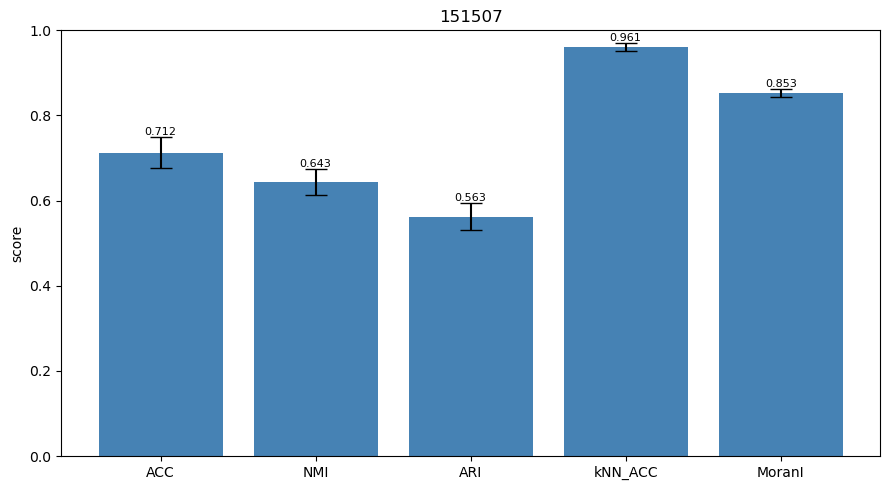

In [11]:
for name, path in METRIC_FILES.items():
    fig, ax = plot_metrics_bar(path, name, metrics=METRICS)
    fig.savefig('./figures/bar_K_CL_ML_%s.png' % name, dpi=150)
plt.show()

In [ ]:
%%bash

# K = 0, ML use，CL use (GAT not use neighbors)
# seeds: 300+
cd "../../src"

f="../data/sample_151507_anno.h5"
for i in {1..5}
do
    python -u run_DSSC.py --n_clusters -1 --data_file $f --save_dir out_151507 \
        --final_labels pred.csv --final_latent_file latent.csv --run $i --seed $((300+i)) \
        --ml_file "../example_constraints/sample_151507_mlFromMarks_test.txt" --cl_file "../example_constraints/sample_151507_clFromMarks_test.txt" \
        --knn 0
done

In [13]:
for name, (h5_path, save_dir) in DATASETS.items():
    df = evaluate_dataset(h5_path, save_dir, seeds=range(301, 306))
    print('=== %s ===' % name)
    display(df.set_index('seed'))
    print('mean +/- std')
    display(summarize_runs(df))
    df.to_csv('./metadata/metrics_CL_ML_%s.csv' % name, index=False)

/hdd2/liuzy/Projects/IntensiveStudy4Lin/DSSC/src/utils.py:94: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  l_mode = stats.mode(labels).mode[0]
/hdd2/liuzy/Projects/IntensiveStudy4Lin/DSSC/src/utils.py:94: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  l_mode = sta

=== 151507 ===


,ACC,NMI,ARI,kNN_ACC,MoranI
seed,,,,,
301,0.428571,0.339702,0.207409,0.555082,0.402227
302,0.433783,0.352199,0.216757,0.567875,0.415518
303,0.417910,0.339308,0.207795,0.543710,0.396245
304,0.470031,0.378360,0.248525,0.614546,0.465174
305,0.467662,0.390089,0.257728,0.626155,0.479211


mean +/- std


,mean,std
ACC,0.443592,0.023768
NMI,0.359932,0.023149
ARI,0.227643,0.023786
kNN_ACC,0.581474,0.036735
MoranI,0.431675,0.037965


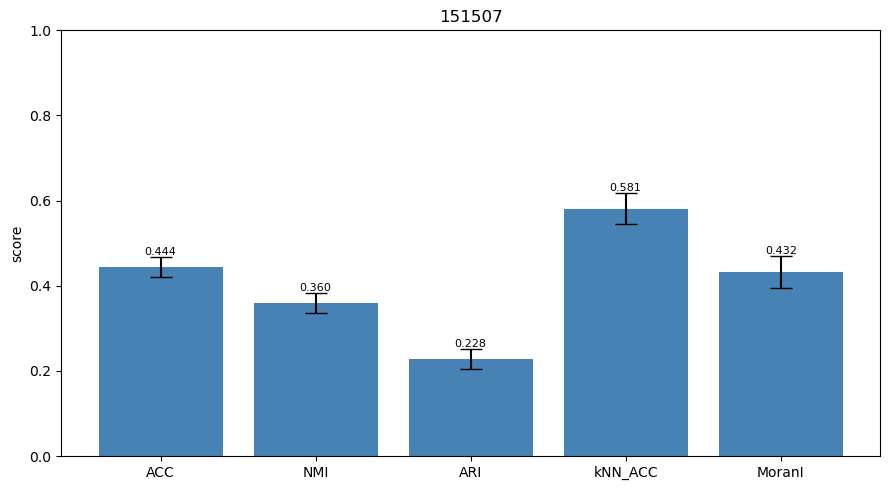

In [14]:
METRICS = ['ACC', 'NMI', 'ARI', 'kNN_ACC', 'MoranI']
METRIC_FILES = {
    '151507': './metadata/metrics_CL_ML_151507.csv',
    # 'osmFISH': './metadata/metrics_osmFISH.csv',
}

for name, path in METRIC_FILES.items():
    fig, ax = plot_metrics_bar(path, name, metrics=METRICS)
    fig.savefig('./figures/bar_CL_ML_%s.png' % name, dpi=150)
plt.show()

In [ ]:
%%bash

# K = 20, ML use，CL not use
# seeds: 400+
cd "../../src"

f="../data/sample_151507_anno.h5"
for i in {1..5}
do
    python -u run_DSSC.py --n_clusters -1 --data_file $f --save_dir out_151507 \
        --final_labels pred.csv --final_latent_file latent.csv --run $i --seed $((400+i)) \
        --ml_file "../example_constraints/sample_151507_mlFromMarks_test.txt" --cl_file "../example_constraints/sample_151507_clFromMarks_test.txt" \
        --no_cl
done
# 1min 39s

In [16]:
for name, (h5_path, save_dir) in DATASETS.items():
    df = evaluate_dataset(h5_path, save_dir, seeds=range(401, 406))
    print('=== %s ===' % name)
    display(df.set_index('seed'))
    print('mean +/- std')
    display(summarize_runs(df))
    df.to_csv('./metadata/metrics_K_ML_%s.csv' % name, index=False)

/hdd2/liuzy/Projects/IntensiveStudy4Lin/DSSC/src/utils.py:94: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  l_mode = stats.mode(labels).mode[0]
/hdd2/liuzy/Projects/IntensiveStudy4Lin/DSSC/src/utils.py:94: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  l_mode = sta

=== 151507 ===


,ACC,NMI,ARI,kNN_ACC,MoranI
seed,,,,,
401,0.560531,0.614593,0.466025,0.961857,0.834020
402,0.685146,0.577497,0.470591,0.965885,0.841850
403,0.693201,0.650099,0.545056,0.960673,0.831995
404,0.690832,0.642117,0.545325,0.966596,0.860471
405,0.712627,0.630272,0.534979,0.953092,0.874390


mean +/- std


,mean,std
ACC,0.668467,0.061218
NMI,0.622915,0.028696
ARI,0.512395,0.040493
kNN_ACC,0.961620,0.005400
MoranI,0.848545,0.018302


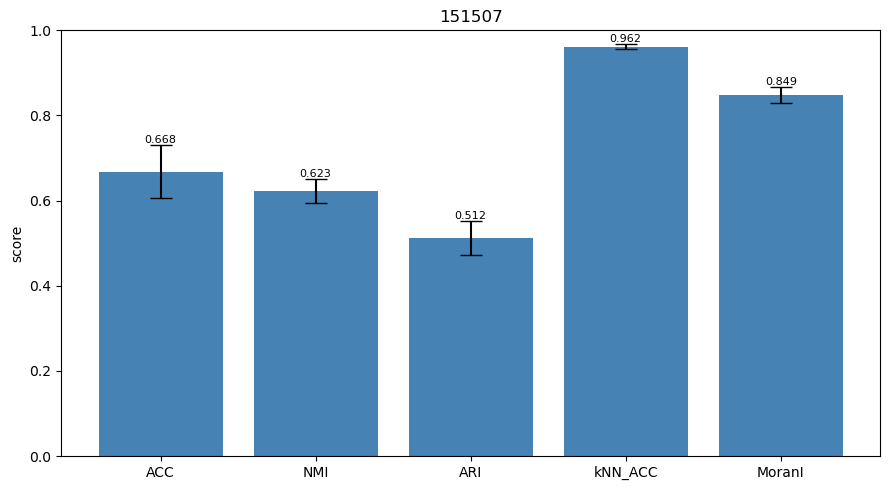

In [17]:
METRICS = ['ACC', 'NMI', 'ARI', 'kNN_ACC', 'MoranI']
METRIC_FILES = {
    '151507': './metadata/metrics_K_ML_151507.csv',
    # 'osmFISH': './metadata/metrics_osmFISH.csv',
}

for name, path in METRIC_FILES.items():
    fig, ax = plot_metrics_bar(path, name, metrics=METRICS)
    fig.savefig('./figures/bar_K_ML_%s.png' % name, dpi=150)
plt.show()